<a href="https://colab.research.google.com/github/zhouqic4/MSSP607-GitHub/blob/main/WeeklyModules/Week07/Week7Participation_activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.options.display.max_rows = 20
plt.rc('figure', figsize=(10, 6))
np.set_printoptions(precision=4, suppress=True)

In [2]:
GITHUB_USER = 'zhouqic4'
REPO        = 'MSSP607-GitHub'
BRANCH      = 'main'
FILE_PATH   = 'data/InternetSales.csv'

url = f'https://raw.githubusercontent.com/{GITHUB_USER}/{REPO}/{BRANCH}/{FILE_PATH}'
print(url)

sales = pd.read_csv(url, encoding='cp1252', low_memory=False)
sales.shape

https://raw.githubusercontent.com/zhouqic4/MSSP607-GitHub/main/data/InternetSales.csv


(60398, 60)

In [3]:
sales[['SalesOrderNumber', 'OrderDate', 'OrderQuantity', 'SalesAmount']].head()

,SalesOrderNumber,OrderDate,OrderQuantity,SalesAmount
0,SO43793,1/19/2011,1,3399.99
1,SO51522,1/18/2013,1,2319.99
2,SO51522,1/18/2013,1,21.98
3,SO57418,5/3/2013,1,2384.07
4,SO57418,5/3/2013,1,28.99


In [4]:
sales['OrderDate'] = pd.to_datetime(sales['OrderDate'], format='%m/%d/%Y')
sales['Year'] = sales['OrderDate'].dt.year
yearly_sales = sales.groupby('Year')['SalesAmount'].sum()
summary = pd.DataFrame({'TotalSales': yearly_sales.round(2),
                        'OrderLines': sales.groupby('Year').size()})
summary

,TotalSales,OrderLines
Year,,
2010,43421.04,14
2011,7075525.93,2216
2012,5842485.20,3397
2013,16351550.34,52801
2014,45694.72,1970


In [5]:
sales.groupby('Year')['OrderDate'].agg(['min', 'max'])

,min,max
Year,,
2010,2010-12-29,2010-12-31
2011,2011-01-01,2011-12-31
2012,2012-01-01,2012-12-31
2013,2013-01-01,2013-12-31
2014,2014-01-01,2014-01-28


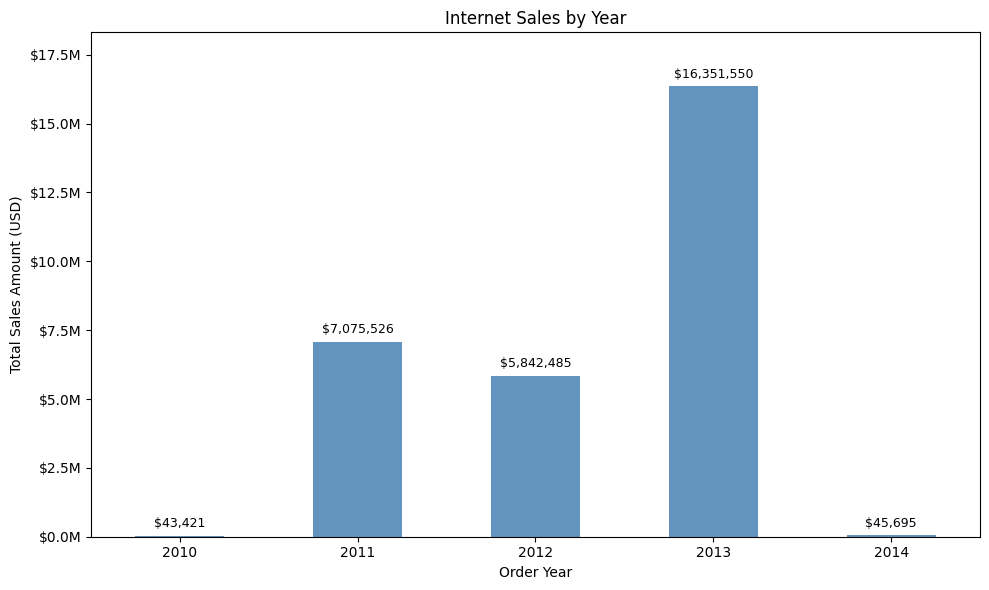

In [7]:
plt.close('all')

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
yearly_sales.plot.bar(ax=ax, color='steelblue', alpha=0.85, rot=0)
ax.set_title('Internet Sales by Year')
ax.set_xlabel('Order Year')
ax.set_ylabel('Total Sales Amount (USD)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, pos: f'${x/1e6:.1f}M'))
for i, value in enumerate(yearly_sales):
    ax.annotate(f'${value:,.0f}', xy=(i, value), xytext=(0, 4),
                textcoords='offset points', ha='center', va='bottom', fontsize=9)

ax.set_ylim(0, yearly_sales.max() * 1.12)
plt.tight_layout()

In [8]:
plt.gcf().savefig('YearlySales.pdf', bbox_inches='tight')
print('Saved YearlySales.pdf')

Saved YearlySales.pdf


<Figure size 1000x600 with 0 Axes>